# 23C — Environmental Context Refinement
## Antecedent dryness + land/water sensitivity before GeoMAE

### Motivation

Notebook 23B gave two important findings:

1. **Emerging-3 is strongly unusual relative to recent local fire history.**
2. The current **environmental anomaly score is weak/model-sensitive**, and Q1 candidates are disproportionately associated with mixed land-water cells.

Therefore, this notebook does **not** proceed to GeoMAE yet.

Instead, it asks:

> Can environmental expectedness be made more stable by using antecedent dryness information and explicit static land/water context, while controlling mixed land-water cells?

### Key corrections

- Uses the locked regional **0.25° T2 dataset**.
- Builds antecedent environmental features directly from the existing 0.25° ERA5 daily features.
- Does **not** reuse the old coarse-grid FWI file.
- Separates:
  - current-day weather,
  - antecedent dryness,
  - static land/water context.
- Uses August only as **development**.
- Restricts predictor dates to **2026-08-01 → 2026-08-30**, so the `t+1` event dates stay inside August.
- September remains untouched by NB23C.

### Interpretation boundary

Even if a hotspot is environmentally unusual, this notebook does **not** infer:
- anthropogenic ignition,
- intentional burning,
- illegal burning,
- plantation clearing,
- cigarette ignition,
- or natural ignition.

This notebook only refines **environmental anomaly**.

In [2]:
# 1. Imports

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 250)
pd.set_option("display.width", 280)

RANDOM_STATE = 42

In [3]:
# 2. Resolve project root

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    candidate = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )
    if candidate.exists():
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/processed/regional_025/"
        "karhut_ml_dataset_regional_025.csv. "
        "Open this notebook from the skripsi-karhut project root "
        "or set PROJECT_ROOT manually."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "environmental_context_refinement"
    / "t2"
)

FIGURES_DIR = RESULTS_DIR / "figures"
EXPORT_DIR = RESULTS_DIR / "exports"

for p in [RESULTS_DIR, FIGURES_DIR, EXPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_PATH   :", DATA_PATH)
print("RESULTS_DIR :", RESULTS_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
DATA_PATH   : c:\Users\Asus\Documents\skripsi-karhut\data\processed\regional_025\karhut_ml_dataset_regional_025.csv
RESULTS_DIR : c:\Users\Asus\Documents\skripsi-karhut\model_results\environmental_context_refinement\t2


In [4]:
# 3. Load locked regional dataset

regional = pd.read_csv(DATA_PATH, parse_dates=["date"])

regional = regional.sort_values(
    ["cell_id", "date"]
).reset_index(drop=True)

print("Rows :", len(regional))
print("Dates:", regional["date"].min().date(), "→", regional["date"].max().date())
print("Nodes:", regional["cell_id"].nunique())

display(regional.head())

Rows : 16625
Dates: 2026-05-08 → 2026-09-09
Nodes: 133


,date,cell_id,fire_count,frp_sum,fire_active,node_index,grid_lat,grid_lon,land_fraction,jrc_mean_water_occurrence,jrc_water_any_fraction,jrc_water50_fraction,jrc_water90_fraction,fire_count_lag1,fire_count_lag3,fire_count_lag7,frp_sum_lag1,frp_sum_lag3,frp_sum_lag7,fire_count_roll3,frp_sum_roll3,fire_count_roll7,frp_sum_roll7,target_fire_active_t1,active_days_prev3_incl_t,event_type_3d,active_days_prev7_incl_t,event_type_7d,temperature_mean,temperature_max,relative_humidity_mean,precipitation_sum,boundary_layer_height_mean,vapour_pressure_deficit_mean,wind_speed_mean,wind_speed_max,wind_u_mean,wind_v_mean
0,2026-05-08,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,Negative,0.0,Negative,26.275000,30.5,91.458333,15.4,238.750000,0.317917,3.929167,5.6,0.691170,-1.995124
1,2026-05-09,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,Negative,0.0,Negative,27.291667,31.2,90.250000,8.2,214.166667,0.386250,3.108333,5.1,0.868119,1.602951
2,2026-05-10,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,Negative,0.0,Negative,26.941667,31.6,89.875000,2.2,175.625000,0.405833,4.250000,7.0,-2.669541,1.563219
3,2026-05-11,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,Negative,0.0,Negative,28.187500,34.2,83.541667,2.3,420.208333,0.734167,3.991667,6.6,-0.189994,1.040999
4,2026-05-12,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,Negative,0.0,Negative,27.291667,31.4,88.416667,6.2,271.041667,0.471250,3.854167,5.4,1.313670,1.731916


In [5]:
# 4. Locked feature definitions

CURRENT_DAY_FIRE_FEATURES = [
    "fire_active",
    "fire_count",
    "frp_sum",
]

FIRE_HISTORY_FEATURES = [
    "fire_count_lag1",
    "fire_count_lag3",
    "fire_count_lag7",
    "frp_sum_lag1",
    "frp_sum_lag3",
    "frp_sum_lag7",
    "fire_count_roll3",
    "fire_count_roll7",
    "frp_sum_roll3",
    "frp_sum_roll7",
]

FIRE13 = CURRENT_DAY_FIRE_FEATURES + FIRE_HISTORY_FEATURES

ENV10 = [
    "temperature_mean",
    "temperature_max",
    "relative_humidity_mean",
    "precipitation_sum",
    "boundary_layer_height_mean",
    "vapour_pressure_deficit_mean",
    "wind_speed_mean",
    "wind_speed_max",
    "wind_u_mean",
    "wind_v_mean",
]

LAND_CONTEXT = [
    c for c in [
        "land_fraction",
        "jrc_mean_water_occurrence",
        "jrc_water_any_fraction",
        "jrc_water50_fraction",
        "jrc_water90_fraction",
    ]
    if c in regional.columns
]

TARGET = "target_fire_active_t1"

required = {
    "date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "active_days_prev3_incl_t",
    "event_type_3d",
    TARGET,
    *FIRE13,
    *ENV10,
    *LAND_CONTEXT,
}

missing = sorted(required - set(regional.columns))
if missing:
    raise ValueError(
        "Missing required columns:\n"
        + "\n".join(f"- {c}" for c in missing)
    )

print("FIRE13 features:", len(FIRE13))
print("ENV10 features :", len(ENV10))
print("LAND features  :", len(LAND_CONTEXT))

FIRE13 features: 13
ENV10 features : 10
LAND features  : 5


# PART A — Build antecedent environmental features

The current ENV10 only describes weather on predictor day `t`.

For fire susceptibility, conditions accumulated over several days can matter.  
We therefore create **transparent rolling summaries** using only day `t` and earlier:

### Antecedent precipitation
- 3-day precipitation sum
- 7-day precipitation sum

### Antecedent dryness
- number of low-rain days (`< 1 mm`) within the last 7 days

### Antecedent atmospheric dryness
- 3-day / 7-day mean VPD
- 3-day / 7-day mean RH

### Antecedent heat / wind
- 3-day / 7-day mean maximum temperature
- 3-day / 7-day mean wind speed

These are **FWI-style antecedent dryness descriptors**, not the Canadian FWI itself.

Why not reuse Notebook 10 FWI directly?

Because the old reusable FWI table was generated from the earlier weather-grid setup.  
NB23C keeps the anomaly analysis spatially consistent with the regional 0.25° T2 dataset.

In [6]:
# 5. Antecedent feature engineering

env = regional.copy()

g = env.groupby("cell_id", group_keys=False)

# Rain accumulation
env["precip_roll3_sum"] = (
    g["precipitation_sum"]
    .rolling(3, min_periods=3)
    .sum()
    .reset_index(level=0, drop=True)
)

env["precip_roll7_sum"] = (
    g["precipitation_sum"]
    .rolling(7, min_periods=7)
    .sum()
    .reset_index(level=0, drop=True)
)

# Number of low-rain days over the latest 7 days.
# This is a transparent exploratory threshold, not a physical ignition label.
env["low_rain_day_lt1mm"] = (
    env["precipitation_sum"] < 1.0
).astype(int)

env["low_rain_days_roll7"] = (
    env.groupby("cell_id")["low_rain_day_lt1mm"]
    .rolling(7, min_periods=7)
    .sum()
    .reset_index(level=0, drop=True)
)

# VPD
for window in [3, 7]:
    env[f"vpd_roll{window}_mean"] = (
        env.groupby("cell_id")["vapour_pressure_deficit_mean"]
        .rolling(window, min_periods=window)
        .mean()
        .reset_index(level=0, drop=True)
    )

# RH
for window in [3, 7]:
    env[f"rh_roll{window}_mean"] = (
        env.groupby("cell_id")["relative_humidity_mean"]
        .rolling(window, min_periods=window)
        .mean()
        .reset_index(level=0, drop=True)
    )

# Maximum temperature
for window in [3, 7]:
    env[f"tempmax_roll{window}_mean"] = (
        env.groupby("cell_id")["temperature_max"]
        .rolling(window, min_periods=window)
        .mean()
        .reset_index(level=0, drop=True)
    )

# Wind speed
for window in [3, 7]:
    env[f"wind_roll{window}_mean"] = (
        env.groupby("cell_id")["wind_speed_mean"]
        .rolling(window, min_periods=window)
        .mean()
        .reset_index(level=0, drop=True)
    )

ANTECEDENT_FEATURES = [
    "precip_roll3_sum",
    "precip_roll7_sum",
    "low_rain_days_roll7",
    "vpd_roll3_mean",
    "vpd_roll7_mean",
    "rh_roll3_mean",
    "rh_roll7_mean",
    "tempmax_roll3_mean",
    "tempmax_roll7_mean",
    "wind_roll3_mean",
    "wind_roll7_mean",
]

print("Antecedent features:", len(ANTECEDENT_FEATURES))

display(
    env[
        [
            "date",
            "cell_id",
            "precipitation_sum",
            *ANTECEDENT_FEATURES,
        ]
    ].head(12)
)

Antecedent features: 11


,date,cell_id,precipitation_sum,precip_roll3_sum,precip_roll7_sum,low_rain_days_roll7,vpd_roll3_mean,vpd_roll7_mean,rh_roll3_mean,rh_roll7_mean,tempmax_roll3_mean,tempmax_roll7_mean,wind_roll3_mean,wind_roll7_mean
0,2026-05-08,regional025_10_22,15.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-05-09,regional025_10_22,8.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-05-10,regional025_10_22,2.2,25.8,NaN,NaN,0.370000,NaN,90.527778,NaN,31.100000,NaN,3.762500,NaN
3,2026-05-11,regional025_10_22,2.3,12.7,NaN,NaN,0.508750,NaN,87.888889,NaN,32.333333,NaN,3.783333,NaN
4,2026-05-12,regional025_10_22,6.2,10.7,NaN,NaN,0.537083,NaN,87.277778,NaN,32.400000,NaN,4.031944,NaN
5,2026-05-13,regional025_10_22,11.2,19.7,NaN,NaN,0.518472,NaN,87.694444,NaN,32.000000,NaN,3.715278,NaN
6,2026-05-14,regional025_10_22,28.3,45.7,73.8,0.0,0.408194,0.438393,89.972222,89.291667,31.300000,31.628571,3.419444,3.648214
7,2026-05-15,regional025_10_22,80.9,120.4,139.3,0.0,0.290278,0.409762,92.652778,90.005952,29.866667,31.142857,2.997222,3.456548
8,2026-05-16,regional025_10_22,23.7,132.9,154.8,0.0,0.345556,0.428274,91.458333,89.619048,30.400000,31.257143,3.426389,3.667857
9,2026-05-17,regional025_10_22,20.8,125.4,173.4,0.0,0.310139,0.412738,91.972222,89.910714,29.700000,31.028571,3.808333,3.667857


In [7]:
# 6. Leakage / chronology sanity checks

# Every rolling feature includes predictor day t and earlier only.
# No shift(-1), target-day weather, or future value is used.

assert not any(
    "target" in c.lower()
    for c in ANTECEDENT_FEATURES
)

# Seven-day rolling summaries should remove the first six rows of each cell.
first_valid = (
    env.dropna(subset=ANTECEDENT_FEATURES)
    .groupby("cell_id")["date"]
    .min()
)

print("Earliest valid antecedent date range:")
print(first_valid.min().date(), "→", first_valid.max().date())

assert first_valid.nunique() == 1, (
    "Expected all cells to obtain 7-day antecedent history on the same date."
)

Earliest valid antecedent date range:
2026-05-14 → 2026-05-14


# PART B — Strict development window

NB23B used predictor dates through August 31, which implies an event date of September 1.

NB23C tightens this:

- Train: valid antecedent rows through **July 31**
- Development predictors: **August 1 → August 30**
- Development event dates: **August 2 → August 31**

Thus **no September target label is used**.

In [8]:
# 7. Train / August development split

TRAIN_END = pd.Timestamp("2026-07-31")
DEV_START = pd.Timestamp("2026-08-01")
DEV_END = pd.Timestamp("2026-08-30")

ALL_MODEL_FEATURES = (
    FIRE13
    + ENV10
    + ANTECEDENT_FEATURES
    + LAND_CONTEXT
)

model_data = env[
    env[ALL_MODEL_FEATURES + [TARGET]]
    .notna()
    .all(axis=1)
].copy()

train = model_data[
    model_data["date"] <= TRAIN_END
].copy()

dev = model_data[
    model_data["date"].between(DEV_START, DEV_END)
].copy()

post_dev = model_data[
    model_data["date"] > DEV_END
].copy()

print(
    "Train:",
    train["date"].min().date(),
    "→",
    train["date"].max().date(),
    "| rows:",
    len(train),
    "| positives:",
    int(train[TARGET].sum()),
    "| rate:",
    round(train[TARGET].mean(), 6),
)

print(
    "Development:",
    dev["date"].min().date(),
    "→",
    dev["date"].max().date(),
    "| target event dates:",
    (dev["date"].min() + pd.Timedelta(days=1)).date(),
    "→",
    (dev["date"].max() + pd.Timedelta(days=1)).date(),
    "| rows:",
    len(dev),
    "| positives:",
    int(dev[TARGET].sum()),
    "| rate:",
    round(dev[TARGET].mean(), 6),
)

print("Rows after Aug-30 excluded from NB23C development:", len(post_dev))

assert train["date"].max() < dev["date"].min()
assert (dev["date"].max() + pd.Timedelta(days=1)) <= pd.Timestamp("2026-08-31")

Train: 2026-05-14 → 2026-07-31 | rows: 10507 | positives: 816 | rate: 0.077663
Development: 2026-08-01 → 2026-08-30 | target event dates: 2026-08-02 → 2026-08-31 | rows: 3990 | positives: 2066 | rate: 0.517794
Rows after Aug-30 excluded from NB23C development: 1330


In [9]:
# 8. Event audit

def event_summary(df, name):
    return {
        "Split": name,
        "Rows": len(df),
        "Dates": df["date"].nunique(),
        "Nodes": df["cell_id"].nunique(),
        "Positives": int(df[TARGET].sum()),
        "Positive rate": float(df[TARGET].mean()),
        "Emerging-3 positives": int(
            (
                df[TARGET].eq(1)
                & df["active_days_prev3_incl_t"].eq(0)
            ).sum()
        ),
        "Persistent positives": int(
            (
                df[TARGET].eq(1)
                & df["active_days_prev3_incl_t"].gt(0)
            ).sum()
        ),
    }

display(
    pd.DataFrame([
        event_summary(train, "Train"),
        event_summary(dev, "August development"),
    ])
)

,Split,Rows,Dates,Nodes,Positives,Positive rate,Emerging-3 positives,Persistent positives
0,Train,10507,79,133,816,0.077663,309,507
1,August development,3990,30,133,2066,0.517794,217,1849


# PART C — Environmental expectedness variants

We compare four formulations.

### E0 — ENV10-LR
Original current-day weather baseline.

### E1 — ENV10 + antecedent dryness (LR)
Tests whether accumulated dryness improves environmental ranking.

### E2 — ENV10 + antecedent dryness + land/water context (LR)
Adds static physical context explicitly.

### E3 — same features as E2, nonlinear HGB
Sensitivity check for model-form dependence.

The purpose is **not** to find a final wildfire predictor.  
The purpose is to see whether environmental anomaly becomes:

- more informative,
- less model-sensitive,
- and less dominated by mixed land-water cells.

In [10]:
# 9. Model helpers

def make_lr():
    return Pipeline([
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=3000,
                random_state=RANDOM_STATE,
            ),
        ),
    ])


def balanced_sample_weights(y):
    y = np.asarray(y).astype(int)
    n = len(y)
    n_pos = max(int((y == 1).sum()), 1)
    n_neg = max(int((y == 0).sum()), 1)

    w_pos = n / (2.0 * n_pos)
    w_neg = n / (2.0 * n_neg)

    return np.where(y == 1, w_pos, w_neg)


E0_FEATURES = ENV10
E1_FEATURES = ENV10 + ANTECEDENT_FEATURES
E2_FEATURES = ENV10 + ANTECEDENT_FEATURES + LAND_CONTEXT

models = {}

models["E0_ENV10_LR"] = (
    make_lr(),
    E0_FEATURES,
)

models["E1_ANTECEDENT_LR"] = (
    make_lr(),
    E1_FEATURES,
)

models["E2_ANTECEDENT_LAND_LR"] = (
    make_lr(),
    E2_FEATURES,
)

models["E3_ANTECEDENT_LAND_HGB"] = (
    HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=180,
        max_leaf_nodes=15,
        min_samples_leaf=30,
        l2_regularization=1.0,
        random_state=RANDOM_STATE,
    ),
    E2_FEATURES,
)

for name, (model, features) in models.items():
    if "HGB" in name:
        model.fit(
            train[features],
            train[TARGET],
            sample_weight=balanced_sample_weights(train[TARGET]),
        )
    else:
        model.fit(
            train[features],
            train[TARGET],
        )

    print("Fitted:", name, "| features:", len(features))

Fitted: E0_ENV10_LR | features: 10
Fitted: E1_ANTECEDENT_LR | features: 21
Fitted: E2_ANTECEDENT_LAND_LR | features: 26
Fitted: E3_ANTECEDENT_LAND_HGB | features: 26


In [11]:
# 10. Score development period

dev_scored = dev.copy()

for name, (model, features) in models.items():
    score_col = f"score__{name}"

    dev_scored[score_col] = model.predict_proba(
        dev_scored[features]
    )[:, 1]

print("Scored development rows:", len(dev_scored))

Scored development rows: 3990


In [12]:
# 11. Performance audit

def metric_bundle(df, score_col):
    y = df[TARGET].to_numpy()
    s = df[score_col].to_numpy()

    out = {
        "Rows": len(df),
        "Positives": int(y.sum()),
        "Prevalence": float(y.mean()),
        "PR-AUC": float(average_precision_score(y, s)),
        "PR-AUC minus prevalence": float(
            average_precision_score(y, s) - y.mean()
        ),
    }

    out["ROC-AUC"] = (
        float(roc_auc_score(y, s))
        if len(np.unique(y)) == 2
        else np.nan
    )

    return out


metric_rows = []

for name in models:
    score_col = f"score__{name}"

    contexts = {
        "Overall": pd.Series(True, index=dev_scored.index),
        "Emerging-3 eligible": dev_scored["active_days_prev3_incl_t"].eq(0),
        "Persistent-context": dev_scored["active_days_prev3_incl_t"].gt(0),
    }

    for context_name, mask in contexts.items():
        metric_rows.append({
            "Model": name,
            "Context": context_name,
            **metric_bundle(
                dev_scored.loc[mask],
                score_col,
            ),
        })

model_metrics = pd.DataFrame(metric_rows)

display(model_metrics)

,Model,Context,Rows,Positives,Prevalence,PR-AUC,PR-AUC minus prevalence,ROC-AUC
0,E0_ENV10_LR,Overall,3990,2066,0.517794,0.593178,0.075383,0.588736
1,E0_ENV10_LR,Emerging-3 eligible,1215,217,0.178601,0.179001,0.000400,0.496768
2,E0_ENV10_LR,Persistent-context,2775,1849,0.666306,0.730283,0.063977,0.588093
3,E1_ANTECEDENT_LR,Overall,3990,2066,0.517794,0.615244,0.097449,0.611971
4,E1_ANTECEDENT_LR,Emerging-3 eligible,1215,217,0.178601,0.170365,-0.008236,0.488248
5,E1_ANTECEDENT_LR,Persistent-context,2775,1849,0.666306,0.762173,0.095866,0.618161
6,E2_ANTECEDENT_LAND_LR,Overall,3990,2066,0.517794,0.645705,0.127910,0.620917
7,E2_ANTECEDENT_LAND_LR,Emerging-3 eligible,1215,217,0.178601,0.175995,-0.002606,0.499469
8,E2_ANTECEDENT_LAND_LR,Persistent-context,2775,1849,0.666306,0.772577,0.106270,0.618035
9,E3_ANTECEDENT_LAND_HGB,Overall,3990,2066,0.517794,0.649946,0.132152,0.647983


## Interpretation rule for metrics

For Emerging-3 eligible rows, the prevalence is the no-skill PR-AUC reference.

If a model has:

`PR-AUC ≈ prevalence`

then it is not meaningfully ranking emerging hotspot outcomes.

This is **not** the only criterion.  
An environmental anomaly definition should also be reasonably stable across model forms.

In [13]:
# 12. Same-day anomaly rank across T2 cells

def within_day_low_score_rank(df, score_col):
    return (
        df.groupby("date")[score_col]
        .transform(
            lambda s: s.rank(
                pct=True,
                ascending=False,
                method="average",
            )
        )
    )


for name in models:
    score_col = f"score__{name}"
    rank_col = f"env_rank__{name}"

    dev_scored[rank_col] = within_day_low_score_rank(
        dev_scored,
        score_col,
    )

# Actual positive events only
pos = dev_scored[
    dev_scored[TARGET].eq(1)
].copy()

pos["event_date"] = (
    pos["date"] + pd.Timedelta(days=1)
)

pos["research_group"] = np.where(
    pos["active_days_prev3_incl_t"].eq(0),
    "Emerging-3",
    "Persistent",
)

print("Positive August events:", len(pos))
print(pos["research_group"].value_counts())

Positive August events: 2066
research_group
Persistent    1849
Emerging-3     217
Name: count, dtype: int64


In [14]:
# 13. Fit history expectedness only for orthogonal two-axis decomposition

history_model = make_lr()
history_model.fit(
    train[FIRE13],
    train[TARGET],
)

dev_scored["history_score"] = history_model.predict_proba(
    dev_scored[FIRE13]
)[:, 1]

dev_scored["history_anomaly_day_rank"] = within_day_low_score_rank(
    dev_scored,
    "history_score",
)

pos = dev_scored[
    dev_scored[TARGET].eq(1)
].copy()

pos["event_date"] = (
    pos["date"] + pd.Timedelta(days=1)
)

pos["research_group"] = np.where(
    pos["active_days_prev3_incl_t"].eq(0),
    "Emerging-3",
    "Persistent",
)

In [15]:
# 14. Emerging vs Persistent environmental anomaly summaries

summary_rows = []

for name in models:
    rank_col = f"env_rank__{name}"

    for group in ["Emerging-3", "Persistent"]:
        subset = pos[
            pos["research_group"].eq(group)
        ]

        summary_rows.append({
            "Model": name,
            "Group": group,
            "Events": len(subset),
            "Mean env anomaly rank": float(subset[rank_col].mean()),
            "Median env anomaly rank": float(subset[rank_col].median()),
        })

env_group_summary = pd.DataFrame(summary_rows)

display(env_group_summary)

,Model,Group,Events,Mean env anomaly rank,Median env anomaly rank
0,E0_ENV10_LR,Emerging-3,217,0.548456,0.571429
1,E0_ENV10_LR,Persistent,1849,0.480333,0.488722
2,E1_ANTECEDENT_LR,Emerging-3,217,0.562489,0.609023
3,E1_ANTECEDENT_LR,Persistent,1849,0.467393,0.466165
4,E2_ANTECEDENT_LAND_LR,Emerging-3,217,0.567201,0.586466
5,E2_ANTECEDENT_LAND_LR,Persistent,1849,0.453466,0.451128
6,E3_ANTECEDENT_LAND_HGB,Emerging-3,217,0.576920,0.605263
7,E3_ANTECEDENT_LAND_HGB,Persistent,1849,0.412749,0.383459


In [16]:
# 15. Date-block bootstrap: Emerging - Persistent median anomaly difference

def date_block_bootstrap_diff(
    df,
    value_col,
    n_boot=2000,
    seed=42,
):
    rng = np.random.default_rng(seed)

    dates = np.array(
        sorted(df["event_date"].unique())
    )

    em = df.loc[
        df["research_group"].eq("Emerging-3"),
        value_col,
    ]

    pe = df.loc[
        df["research_group"].eq("Persistent"),
        value_col,
    ]

    observed = float(
        em.median() - pe.median()
    )

    boot = []

    for _ in range(n_boot):
        sampled_dates = rng.choice(
            dates,
            size=len(dates),
            replace=True,
        )

        pieces = [
            df[df["event_date"].eq(d)]
            for d in sampled_dates
        ]

        b = pd.concat(
            pieces,
            ignore_index=True,
        )

        bem = b.loc[
            b["research_group"].eq("Emerging-3"),
            value_col,
        ]

        bpe = b.loc[
            b["research_group"].eq("Persistent"),
            value_col,
        ]

        if len(bem) == 0 or len(bpe) == 0:
            continue

        boot.append(
            float(
                bem.median()
                - bpe.median()
            )
        )

    lo, hi = np.quantile(
        boot,
        [0.025, 0.975],
    )

    return {
        "Rank": value_col,
        "Observed median difference": observed,
        "Bootstrap 2.5%": float(lo),
        "Bootstrap 97.5%": float(hi),
        "Bootstrap samples": len(boot),
    }


bootstrap_results = pd.DataFrame([
    date_block_bootstrap_diff(
        pos,
        f"env_rank__{name}",
    )
    for name in models
])

display(bootstrap_results)

,Rank,Observed median difference,Bootstrap 2.5%,Bootstrap 97.5%,Bootstrap samples
0,env_rank__E0_ENV10_LR,0.082707,0.022556,0.157895,2000
1,env_rank__E1_ANTECEDENT_LR,0.142857,0.075188,0.199248,2000
2,env_rank__E2_ANTECEDENT_LAND_LR,0.135338,0.093985,0.206767,2000
3,env_rank__E3_ANTECEDENT_LAND_HGB,0.221805,0.165414,0.263158,2000


# PART D — Model-form stability

NB23B's main problem was that LR and HGB environmental anomaly rankings disagreed substantially.

The most relevant comparison here is:

- **E2** refined environmental context with LR
- **E3** exactly the same inputs with nonlinear HGB

If these two still disagree strongly, we should not freeze an environmental anomaly label yet.

In [17]:
# 16. Refined LR vs refined HGB robustness

LR_RANK = "env_rank__E2_ANTECEDENT_LAND_LR"
HGB_RANK = "env_rank__E3_ANTECEDENT_LAND_HGB"

rank_corr = (
    pos[LR_RANK]
    .rank(method="average")
    .corr(
        pos[HGB_RANK]
        .rank(method="average")
    )
)

THRESHOLD = 0.80

lr_high = pos[LR_RANK] >= THRESHOLD
hgb_high = pos[HGB_RANK] >= THRESHOLD

intersection = int((lr_high & hgb_high).sum())
union = int((lr_high | hgb_high).sum())

jaccard = (
    intersection / union
    if union
    else np.nan
)

robustness = pd.DataFrame({
    "Metric": [
        "Refined LR vs HGB rank correlation",
        "Top-20% Jaccard",
        "LR high-env positives",
        "HGB high-env positives",
        "Intersection",
    ],
    "Value": [
        rank_corr,
        jaccard,
        int(lr_high.sum()),
        int(hgb_high.sum()),
        intersection,
    ],
})

display(robustness)

,Metric,Value
0,Refined LR vs HGB rank correlation,0.378421
1,Top-20% Jaccard,0.232759
2,LR high-env positives,324.000000
3,HGB high-env positives,248.000000
4,Intersection,108.000000


In [18]:
# 17. Compare NB23B-style baseline stability vs refined stability

BASE_LR = "env_rank__E0_ENV10_LR"

baseline_vs_refined = pd.DataFrame({
    "Comparison": [
        "Base ENV10 LR vs refined E2 LR",
        "Refined E2 LR vs refined E3 HGB",
    ],
    "Rank correlation": [
        pos[BASE_LR].rank().corr(
            pos[LR_RANK].rank()
        ),
        pos[LR_RANK].rank().corr(
            pos[HGB_RANK].rank()
        ),
    ],
})

display(baseline_vs_refined)

,Comparison,Rank correlation
0,Base ENV10 LR vs refined E2 LR,0.859390
1,Refined E2 LR vs refined E3 HGB,0.378421


# PART E — Land/water sensitivity

NB23B showed that Q1 candidates had substantially lower land fraction and higher JRC water fractions.

NB23C therefore does not simply discard coastal cells.

Instead, it reports sensitivity at:

- all retained T2 cells,
- `land_fraction >= 0.80`,
- `land_fraction >= 0.95`.

If anomaly conclusions disappear when mixed cells are restricted, then the original anomaly set was spatially fragile.

In [19]:
# 18. Land-fraction sensitivity of refined environmental anomaly

land_threshold_rows = []

for land_threshold in [0.0, 0.80, 0.95]:
    subset = pos[
        pos["land_fraction"] >= land_threshold
    ].copy()

    for group in ["Emerging-3", "Persistent"]:
        gsub = subset[
            subset["research_group"].eq(group)
        ]

        land_threshold_rows.append({
            "Land fraction threshold": land_threshold,
            "Group": group,
            "Events": len(gsub),
            "E2 LR median env rank": (
                float(gsub[LR_RANK].median())
                if len(gsub)
                else np.nan
            ),
            "E3 HGB median env rank": (
                float(gsub[HGB_RANK].median())
                if len(gsub)
                else np.nan
            ),
        })

land_sensitivity = pd.DataFrame(
    land_threshold_rows
)

display(land_sensitivity)

,Land fraction threshold,Group,Events,E2 LR median env rank,E3 HGB median env rank
0,0.00,Emerging-3,217,0.586466,0.605263
1,0.00,Persistent,1849,0.451128,0.383459
2,0.80,Emerging-3,186,0.552632,0.560150
3,0.80,Persistent,1632,0.428571,0.368421
4,0.95,Emerging-3,172,0.541353,0.556391
5,0.95,Persistent,1583,0.436090,0.375940


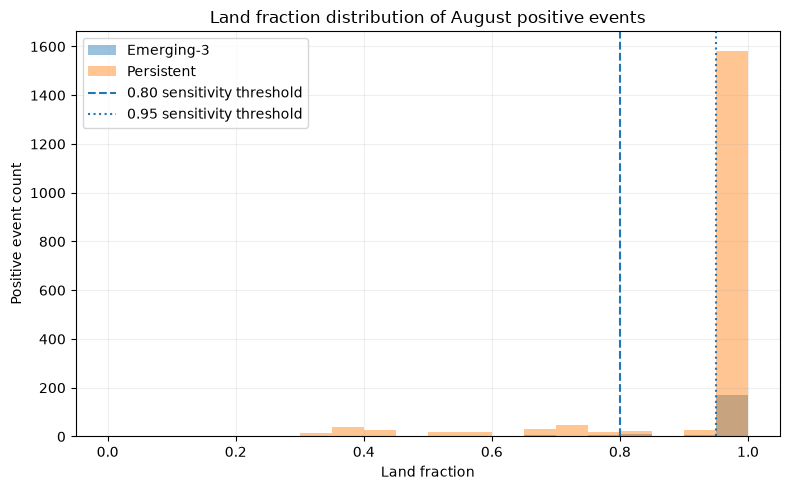

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\environmental_context_refinement\t2\figures\01_positive_event_land_fraction.png


In [20]:
# 19. Plot land-fraction distribution for positive events

fig, ax = plt.subplots(figsize=(8, 5))

for group, subset in pos.groupby("research_group"):
    ax.hist(
        subset["land_fraction"],
        bins=np.linspace(0, 1, 21),
        alpha=0.45,
        label=group,
    )

ax.axvline(
    0.80,
    linestyle="--",
    label="0.80 sensitivity threshold",
)

ax.axvline(
    0.95,
    linestyle=":",
    label="0.95 sensitivity threshold",
)

ax.set_xlabel("Land fraction")
ax.set_ylabel("Positive event count")
ax.set_title("Land fraction distribution of August positive events")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

path = FIGURES_DIR / "01_positive_event_land_fraction.png"
plt.savefig(path, dpi=190, bbox_inches="tight")
plt.show()

print("Saved:", path)

# PART F — Robust Q1 candidates

To avoid over-relying on one environmental model, NB23C defines a **robust exploratory candidate** as:

- history anomaly rank ≥ 0.80
- refined environmental LR rank ≥ 0.80
- refined environmental HGB rank ≥ 0.80

This is an **intersection**, not a trained classification label.

We then separately inspect:
- all robust candidates,
- robust candidates with `land_fraction >= 0.80`,
- robust candidates with `land_fraction >= 0.95`.

Again:

> robust Q1 ≠ anthropogenic.

In [21]:
# 20. Robust candidate definition

pos["high_history"] = (
    pos["history_anomaly_day_rank"]
    >= THRESHOLD
)

pos["high_env_refined_lr"] = (
    pos[LR_RANK]
    >= THRESHOLD
)

pos["high_env_refined_hgb"] = (
    pos[HGB_RANK]
    >= THRESHOLD
)

pos["robust_joint_high"] = (
    pos["high_history"]
    & pos["high_env_refined_lr"]
    & pos["high_env_refined_hgb"]
)

robust_candidates = (
    pos[
        pos["robust_joint_high"]
    ]
    .copy()
)

robust_candidates["robust_joint_score"] = (
    robust_candidates[
        [
            "history_anomaly_day_rank",
            LR_RANK,
            HGB_RANK,
        ]
    ]
    .mean(axis=1)
)

robust_candidates = (
    robust_candidates
    .sort_values(
        "robust_joint_score",
        ascending=False,
    )
)

print("Robust joint-high candidates:", len(robust_candidates))
print(
    "Emerging-3:",
    int(
        robust_candidates[
            "research_group"
        ].eq("Emerging-3").sum()
    ),
)
print(
    "Persistent:",
    int(
        robust_candidates[
            "research_group"
        ].eq("Persistent").sum()
    ),
)

Robust joint-high candidates: 20
Emerging-3: 19
Persistent: 1


In [22]:
# 21. Candidate counts under land sensitivity

candidate_land_summary = pd.DataFrame([
    {
        "Land threshold": threshold,
        "Candidates": int(
            (
                robust_candidates["land_fraction"]
                >= threshold
            ).sum()
        ),
        "Emerging-3": int(
            (
                (robust_candidates["land_fraction"] >= threshold)
                & robust_candidates["research_group"].eq("Emerging-3")
            ).sum()
        ),
        "Persistent": int(
            (
                (robust_candidates["land_fraction"] >= threshold)
                & robust_candidates["research_group"].eq("Persistent")
            ).sum()
        ),
    }
    for threshold in [0.0, 0.80, 0.95]
])

display(candidate_land_summary)

,Land threshold,Candidates,Emerging-3,Persistent
0,0.00,20,19,1
1,0.80,9,8,1
2,0.95,6,6,0


In [23]:
# 22. Top robust candidate table

candidate_cols = [
    "event_date",
    "date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "research_group",
    "land_fraction",
    "jrc_mean_water_occurrence",
    "jrc_water_any_fraction",
    "jrc_water50_fraction",
    "jrc_water90_fraction",
    "active_days_prev3_incl_t",
    "fire_active",
    "fire_count",
    "frp_sum",
    "temperature_mean",
    "temperature_max",
    "relative_humidity_mean",
    "precipitation_sum",
    "vapour_pressure_deficit_mean",
    "precip_roll3_sum",
    "precip_roll7_sum",
    "low_rain_days_roll7",
    "vpd_roll3_mean",
    "vpd_roll7_mean",
    "rh_roll3_mean",
    "rh_roll7_mean",
    "history_anomaly_day_rank",
    LR_RANK,
    HGB_RANK,
    "robust_joint_score",
]

candidate_cols = [
    c for c in candidate_cols
    if c in robust_candidates.columns
]

display(
    robust_candidates[
        candidate_cols
    ].head(40)
)

,event_date,date,cell_id,grid_lat,grid_lon,research_group,land_fraction,jrc_mean_water_occurrence,jrc_water_any_fraction,jrc_water50_fraction,jrc_water90_fraction,active_days_prev3_incl_t,fire_active,fire_count,frp_sum,temperature_mean,temperature_max,relative_humidity_mean,precipitation_sum,vapour_pressure_deficit_mean,precip_roll3_sum,precip_roll7_sum,low_rain_days_roll7,vpd_roll3_mean,vpd_roll7_mean,rh_roll3_mean,rh_roll7_mean,history_anomaly_day_rank,env_rank__E2_ANTECEDENT_LAND_LR,env_rank__E3_ANTECEDENT_LAND_HGB,robust_joint_score
15108,2026-08-25,2026-08-24,regional025_8_34,-2.375,116.625,Emerging-3,0.281019,73.065750,0.748730,0.744526,0.739155,0.0,0,0.0,0.0,27.400000,27.8,75.916667,0.0,0.880417,0.0,0.0,7.0,0.886250,0.917619,75.916667,75.047619,0.936090,0.984962,0.984962,0.968672
9109,2026-08-26,2026-08-25,regional025_4_32,-3.375,116.125,Emerging-3,0.207898,19.817924,0.242897,0.196074,0.185449,0.0,0,0.0,0.0,26.958333,29.4,74.250000,0.0,0.945833,0.0,0.0,7.0,0.910139,0.907619,75.472222,75.642857,0.932331,1.000000,0.954887,0.962406
11976,2026-08-18,2026-08-17,regional025_6_33,-2.875,116.375,Emerging-3,0.380947,62.648907,0.643862,0.635383,0.629557,0.0,0,0.0,0.0,27.516667,28.1,77.208333,0.0,0.840000,0.0,0.1,7.0,0.850972,0.862083,76.944444,76.714286,0.857143,0.984962,0.984962,0.942356
13487,2026-08-29,2026-08-28,regional025_7_33,-2.625,116.375,Emerging-3,0.463438,50.938248,0.542637,0.514815,0.500421,0.0,0,0.0,0.0,26.925000,29.3,73.208333,0.0,0.978750,0.0,0.0,7.0,1.004722,0.999048,72.875000,73.226190,0.909774,0.962406,0.909774,0.927318
8092,2026-08-09,2026-08-08,regional025_4_24,-3.375,114.125,Emerging-3,0.408378,53.728271,0.562401,0.550079,0.530919,0.0,0,0.0,0.0,27.341667,32.2,71.958333,0.0,1.111667,0.0,0.0,7.0,1.104028,1.042798,72.333333,74.202381,0.887218,0.924812,0.954887,0.922306
6109,2026-08-26,2026-08-25,regional025_13_33,-1.125,116.375,Emerging-3,1.000000,0.003370,0.000227,0.000010,0.000000,0.0,0,0.0,0.0,26.283333,32.4,73.416667,0.0,1.082500,0.1,0.1,7.0,1.031944,1.003214,74.750000,75.601190,0.932331,0.842105,0.969925,0.914787
4484,2026-08-26,2026-08-25,regional025_12_33,-1.375,116.375,Emerging-3,1.000000,0.013415,0.001534,0.000014,0.000000,0.0,0,0.0,0.0,26.595833,32.5,73.958333,0.0,1.074167,0.1,0.2,7.0,1.024306,0.986786,75.472222,76.380952,0.857143,0.894737,0.977444,0.909774
11972,2026-08-14,2026-08-13,regional025_6_33,-2.875,116.375,Emerging-3,0.380947,62.648907,0.643862,0.635383,0.629557,0.0,0,0.0,0.0,27.875000,28.1,77.541667,0.0,0.843333,0.1,0.1,7.0,0.905972,0.976786,75.569444,73.440476,0.917293,0.834586,0.977444,0.909774
11855,2026-08-22,2026-08-21,regional025_6_32,-2.875,116.125,Persistent,0.818806,14.682302,0.157834,0.149838,0.143560,1.0,0,0.0,0.0,27.391667,30.2,75.583333,0.0,0.935000,0.0,0.0,7.0,0.972500,0.977976,74.555556,74.666667,0.864662,0.962406,0.879699,0.902256
11839,2026-08-06,2026-08-05,regional025_6_32,-2.875,116.125,Emerging-3,0.818806,14.682302,0.157834,0.149838,0.143560,0.0,0,0.0,0.0,27.366667,30.3,78.875000,0.0,0.808333,0.2,4.5,5.0,0.816389,0.778274,78.694444,79.559524,0.819549,0.977444,0.902256,0.899749


In [24]:
# 23. Spatial concentration audit

cell_audit = (
    robust_candidates
    .groupby(
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
            "land_fraction",
        ]
    )
    .agg(
        candidate_events=("event_date", "size"),
        emerging_events=(
            "research_group",
            lambda s: int(
                s.eq("Emerging-3").sum()
            ),
        ),
        mean_robust_score=(
            "robust_joint_score",
            "mean",
        ),
    )
    .reset_index()
    .sort_values(
        [
            "candidate_events",
            "mean_robust_score",
        ],
        ascending=False,
    )
)

display(cell_audit.head(25))

if len(robust_candidates):
    top5_share = (
        cell_audit[
            "candidate_events"
        ].head(5).sum()
        / len(robust_candidates)
    )
else:
    top5_share = np.nan

print(
    "Share of robust candidates in top 5 cells:",
    round(top5_share, 4),
)

,cell_id,grid_lat,grid_lon,land_fraction,candidate_events,emerging_events,mean_robust_score
5,regional025_6_32,-2.875,116.125,0.818806,3,2,0.898914
3,regional025_4_24,-3.375,114.125,0.408378,3,3,0.870927
6,regional025_6_33,-2.875,116.375,0.380947,2,2,0.926065
10,regional025_8_34,-2.375,116.625,0.281019,2,2,0.922932
0,regional025_12_33,-1.375,116.375,1.000000,2,2,0.886591
7,regional025_7_32,-2.625,116.125,1.000000,2,2,0.857769
4,regional025_4_32,-3.375,116.125,0.207898,1,1,0.962406
8,regional025_7_33,-2.625,116.375,0.463438,1,1,0.927318
1,regional025_13_33,-1.125,116.375,1.000000,1,1,0.914787
11,regional025_9_33,-2.125,116.375,0.680458,1,1,0.888471


Share of robust candidates in top 5 cells: 0.6


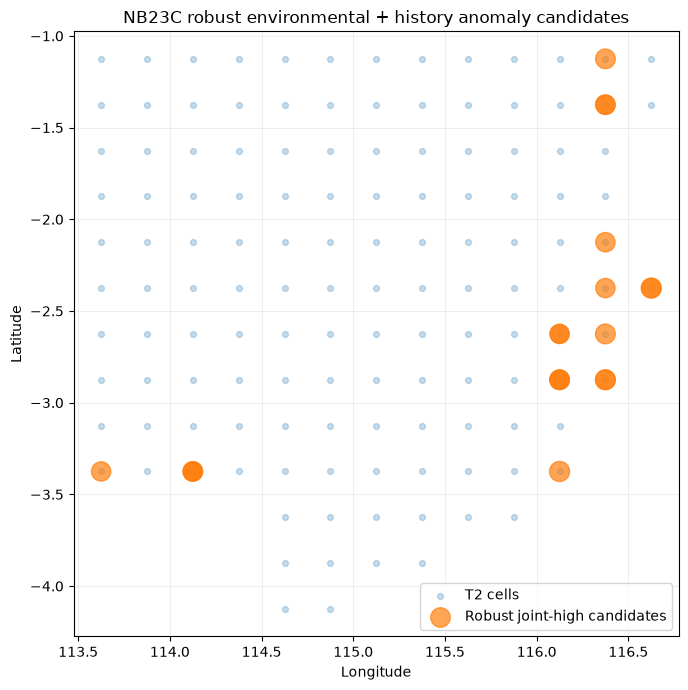

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\environmental_context_refinement\t2\figures\02_robust_joint_high_map.png


In [25]:
# 24. Spatial map

fig, ax = plt.subplots(figsize=(8, 7))

nodes = (
    dev_scored[
        [
            "cell_id",
            "grid_lon",
            "grid_lat",
            "land_fraction",
        ]
    ]
    .drop_duplicates()
)

ax.scatter(
    nodes["grid_lon"],
    nodes["grid_lat"],
    s=18,
    alpha=0.25,
    label="T2 cells",
)

if len(robust_candidates):
    ax.scatter(
        robust_candidates["grid_lon"],
        robust_candidates["grid_lat"],
        s=(
            35
            + 180
            * robust_candidates[
                "robust_joint_score"
            ].to_numpy()
        ),
        alpha=0.70,
        label="Robust joint-high candidates",
    )

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("NB23C robust environmental + history anomaly candidates")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

path = FIGURES_DIR / "02_robust_joint_high_map.png"
plt.savefig(path, dpi=190, bbox_inches="tight")
plt.show()

print("Saved:", path)

In [26]:
# 25. Threshold sensitivity: 0.75 / 0.80 / 0.90

threshold_rows = []

for q in [0.75, 0.80, 0.90]:
    joint = (
        (pos["history_anomaly_day_rank"] >= q)
        & (pos[LR_RANK] >= q)
        & (pos[HGB_RANK] >= q)
    )

    for land_threshold in [0.0, 0.80, 0.95]:
        mask = (
            joint
            & (
                pos["land_fraction"]
                >= land_threshold
            )
        )

        threshold_rows.append({
            "Rank threshold": q,
            "Land threshold": land_threshold,
            "Candidates": int(mask.sum()),
            "Emerging-3": int(
                (
                    mask
                    & pos["research_group"].eq("Emerging-3")
                ).sum()
            ),
            "Persistent": int(
                (
                    mask
                    & pos["research_group"].eq("Persistent")
                ).sum()
            ),
        })

threshold_sensitivity = pd.DataFrame(
    threshold_rows
)

display(threshold_sensitivity)

,Rank threshold,Land threshold,Candidates,Emerging-3,Persistent
0,0.75,0.00,35,27,8
1,0.75,0.80,16,11,5
2,0.75,0.95,11,8,3
3,0.80,0.00,20,19,1
4,0.80,0.80,9,8,1
5,0.80,0.95,6,6,0
6,0.90,0.00,3,3,0
7,0.90,0.80,0,0,0
8,0.90,0.95,0,0,0


# PART G — Decision gate before GeoMAE

NB23C should answer five questions:

### Q1. Did antecedent dryness improve environmental ranking?
Compare E0 vs E1 / E2, especially on **Emerging-3 eligible** rows.

### Q2. Did explicit land/water context reduce model instability?
Compare E2 LR vs E3 HGB:
- rank correlation
- top-20% Jaccard

### Q3. Are robust candidates still dominated by mixed land-water cells?
Inspect:
- candidate count at land fraction 0.80 / 0.95
- top-cell concentration
- candidate map

### Q4. Does the candidate set survive reasonable thresholds?
Check rank thresholds:
- 0.75
- 0.80
- 0.90

### Q5. Is environmental anomaly now scientifically useful?
If environmental models still perform near no-skill for Emerging-3 and disagree strongly,
do **not** freeze the anomaly label.

In that case the next priority becomes **external context acquisition**, especially:
- lightning,
- land cover / land use,
- land-cover change,
- roads / accessibility,
- peatland / canal context.

If environmental anomaly becomes sufficiently stable, proceed to:
> **NB24 — GeoMAE-inspired masked spatiotemporal representation learning**

In [27]:
# 26. Save outputs

MODEL_METRICS_PATH = EXPORT_DIR / "model_metrics.csv"
GROUP_SUMMARY_PATH = EXPORT_DIR / "environmental_group_summary.csv"
BOOTSTRAP_PATH = EXPORT_DIR / "bootstrap_environmental_differences.csv"
ROBUSTNESS_PATH = EXPORT_DIR / "refined_model_robustness.csv"
LAND_SENSITIVITY_PATH = EXPORT_DIR / "land_fraction_sensitivity.csv"
CANDIDATE_PATH = EXPORT_DIR / "robust_joint_high_candidates.csv"
CELL_AUDIT_PATH = EXPORT_DIR / "candidate_cell_audit.csv"
THRESHOLD_PATH = EXPORT_DIR / "threshold_sensitivity.csv"
ALL_POS_PATH = EXPORT_DIR / "august_positive_refined_anomaly.csv"
METADATA_PATH = EXPORT_DIR / "nb23c_methodology_metadata.json"

model_metrics.to_csv(
    MODEL_METRICS_PATH,
    index=False,
)

env_group_summary.to_csv(
    GROUP_SUMMARY_PATH,
    index=False,
)

bootstrap_results.to_csv(
    BOOTSTRAP_PATH,
    index=False,
)

robustness.to_csv(
    ROBUSTNESS_PATH,
    index=False,
)

land_sensitivity.to_csv(
    LAND_SENSITIVITY_PATH,
    index=False,
)

robust_candidates.to_csv(
    CANDIDATE_PATH,
    index=False,
)

cell_audit.to_csv(
    CELL_AUDIT_PATH,
    index=False,
)

threshold_sensitivity.to_csv(
    THRESHOLD_PATH,
    index=False,
)

pos.to_csv(
    ALL_POS_PATH,
    index=False,
)

metadata = {
    "notebook": "23C_environmental_context_refinement",
    "spatial_domain": "locked T2 regional 0.25 degree grid",
    "train_end": str(TRAIN_END.date()),
    "development_predictor_start": str(DEV_START.date()),
    "development_predictor_end": str(DEV_END.date()),
    "development_latest_target_date": str(
        (
            DEV_END
            + pd.Timedelta(days=1)
        ).date()
    ),
    "september_target_labels_used": False,
    "target": TARGET,
    "antecedent_features": ANTECEDENT_FEATURES,
    "land_context_features": LAND_CONTEXT,
    "primary_refined_lr": "E2_ANTECEDENT_LAND_LR",
    "primary_refined_hgb_sensitivity": "E3_ANTECEDENT_LAND_HGB",
    "robust_candidate_definition": (
        "history same-day anomaly rank >= 0.80 AND "
        "refined LR environmental rank >= 0.80 AND "
        "refined HGB environmental rank >= 0.80"
    ),
    "important_limit": (
        "Robust joint-high candidates are not labels of anthropogenic, "
        "intentional, illegal, plantation-related, cigarette-related, "
        "or natural ignition."
    ),
}

METADATA_PATH.write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print("Saved outputs to:", EXPORT_DIR)

Saved outputs to: c:\Users\Asus\Documents\skripsi-karhut\model_results\environmental_context_refinement\t2\exports


In [28]:
# 27. Automatic review summary

print("=== NB23C automatic review ===")
print()

emerging_metrics = (
    model_metrics[
        model_metrics["Context"]
        .eq("Emerging-3 eligible")
    ][
        [
            "Model",
            "Prevalence",
            "PR-AUC",
            "PR-AUC minus prevalence",
            "ROC-AUC",
        ]
    ]
)

display(emerging_metrics)

print()
display(robustness)

print()
display(candidate_land_summary)

print()

corr = float(
    robustness.loc[
        robustness["Metric"]
        .eq("Refined LR vs HGB rank correlation"),
        "Value",
    ].iloc[0]
)

jac = float(
    robustness.loc[
        robustness["Metric"]
        .eq("Top-20% Jaccard"),
        "Value",
    ].iloc[0]
)

print(
    f"Refined LR/HGB rank correlation: {corr:.3f}"
)

print(
    f"Refined top-20% Jaccard        : {jac:.3f}"
)

print(
    f"Robust joint-high candidates   : {len(robust_candidates)}"
)

if len(robust_candidates):
    print(
        "Robust candidates land>=0.80 :",
        int(
            (
                robust_candidates["land_fraction"]
                >= 0.80
            ).sum()
        ),
    )

    print(
        "Robust candidates land>=0.95 :",
        int(
            (
                robust_candidates["land_fraction"]
                >= 0.95
            ).sum()
        ),
    )

print()

if corr >= 0.70 and jac >= 0.40:
    print(
        "Heuristic: environmental ranking is substantially more stable. "
        "Review metrics and land sensitivity before proceeding to NB24."
    )
else:
    print(
        "Heuristic: environmental ranking is still model-sensitive. "
        "Do not freeze an anomaly label yet; external context or further "
        "environmental refinement is likely needed."
    )

print()
print(
    "This heuristic is a workflow aid, not a statistical acceptance criterion."
)

=== NB23C automatic review ===



,Model,Prevalence,PR-AUC,PR-AUC minus prevalence,ROC-AUC
1,E0_ENV10_LR,0.178601,0.179001,0.000400,0.496768
4,E1_ANTECEDENT_LR,0.178601,0.170365,-0.008236,0.488248
7,E2_ANTECEDENT_LAND_LR,0.178601,0.175995,-0.002606,0.499469
10,E3_ANTECEDENT_LAND_HGB,0.178601,0.201944,0.023343,0.541327


,Metric,Value
0,Refined LR vs HGB rank correlation,0.378421
1,Top-20% Jaccard,0.232759
2,LR high-env positives,324.000000
3,HGB high-env positives,248.000000
4,Intersection,108.000000


,Land threshold,Candidates,Emerging-3,Persistent
0,0.00,20,19,1
1,0.80,9,8,1
2,0.95,6,6,0



Refined LR/HGB rank correlation: 0.378
Refined top-20% Jaccard        : 0.233
Robust joint-high candidates   : 20
Robust candidates land>=0.80 : 9
Robust candidates land>=0.95 : 6

Heuristic: environmental ranking is still model-sensitive. Do not freeze an anomaly label yet; external context or further environmental refinement is likely needed.

This heuristic is a workflow aid, not a statistical acceptance criterion.


# What to send for review

After **Run All**, send the executed NB23C notebook.

The most important outputs are:

1. Emerging-3 rows from `model_metrics`
2. `bootstrap_results`
3. `robustness`
4. `land_sensitivity`
5. `candidate_land_summary`
6. `threshold_sensitivity`
7. top rows of `robust_candidates`
8. `cell_audit`
9. Figures 01–02

Then we decide the next branch:

### Branch A — refined environmental anomaly is stable enough
→ **NB24 GeoMAE-inspired masked spatiotemporal pretraining**

### Branch B — still weak/model-sensitive
→ acquire external contextual data first:
**lightning + land cover/change + accessibility**, then reformulate anomaly context.